In [1]:
# Polynomial Regression : Here the independent features X are not linearly dependent with the y

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

In [33]:
# We will create a non linear dataset
X= 6 * np.random.rand(100,1) - 3
X

array([[-1.04581149],
       [-1.85907425],
       [ 0.784103  ],
       [-2.84075048],
       [ 1.35179154],
       [-2.65322611],
       [-0.7621566 ],
       [ 0.78549308],
       [-1.30552098],
       [-2.11448562],
       [ 1.37568452],
       [ 1.49320867],
       [-2.55373289],
       [ 0.75198439],
       [-1.29896556],
       [ 1.05567481],
       [ 0.24989832],
       [ 1.37595776],
       [-1.66043841],
       [ 2.3317598 ],
       [-2.28806528],
       [ 2.82717373],
       [ 0.6075071 ],
       [-1.72629144],
       [-1.12224855],
       [-1.92408316],
       [-1.89455769],
       [ 0.9892384 ],
       [ 2.96572705],
       [-2.79606849],
       [ 0.51433441],
       [ 2.4330694 ],
       [-2.27732474],
       [-1.68748533],
       [ 1.06281202],
       [-1.44832946],
       [-2.70499405],
       [-0.58841436],
       [-0.54593787],
       [-0.022115  ],
       [ 1.05531128],
       [-2.45950612],
       [ 2.12048439],
       [ 0.95921236],
       [-2.17143984],
       [-1

In [34]:
y=0.5 * X**2 + 1.5*X + 2 + np.random.rand(100,1)
# quadratic equation used - y=0.5x^2+1.5x+2+outliers
y

array([[ 1.07807493],
       [ 1.73918926],
       [ 4.01613512],
       [ 2.67810592],
       [ 5.14524454],
       [ 1.92102213],
       [ 1.5102402 ],
       [ 3.93901136],
       [ 1.0957168 ],
       [ 1.90969551],
       [ 5.35818056],
       [ 6.26901818],
       [ 1.95318094],
       [ 4.38183821],
       [ 1.11759545],
       [ 5.0783385 ],
       [ 3.17682577],
       [ 5.36903527],
       [ 1.65146892],
       [ 8.3077215 ],
       [ 1.24088522],
       [11.07885645],
       [ 3.16008405],
       [ 1.00970592],
       [ 1.42795351],
       [ 1.682011  ],
       [ 1.37585697],
       [ 4.22934429],
       [11.60311427],
       [ 1.86278433],
       [ 3.37107248],
       [ 8.70654725],
       [ 1.38827764],
       [ 1.4509071 ],
       [ 4.83801205],
       [ 1.26470322],
       [ 2.23477463],
       [ 1.92711249],
       [ 2.26833455],
       [ 2.11015421],
       [ 4.28611855],
       [ 1.4847369 ],
       [ 8.11016389],
       [ 4.81254573],
       [ 1.12906981],
       [ 1

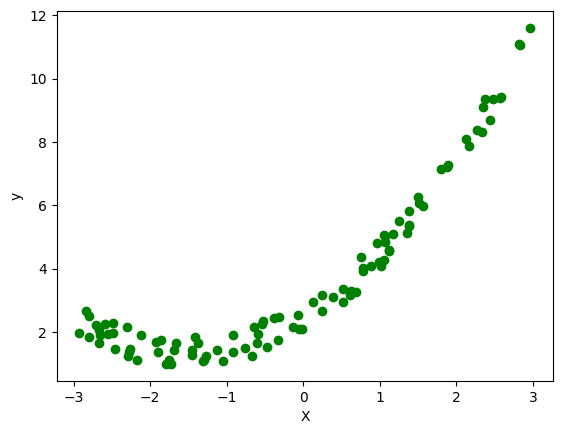

In [35]:
plt.scatter(X,y,color="g")
plt.xlabel("X")
plt.ylabel("y")
plt.show()

In [36]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [37]:
# Lets check for Simple Linear Regression First
from sklearn.linear_model import LinearRegression
regression_1=LinearRegression(n_jobs=-1)

In [38]:
regression_1.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",-1
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


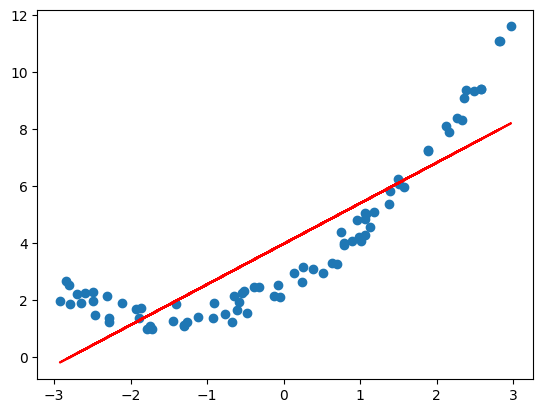

In [42]:
plt.scatter(X_train,y_train)
plt.plot(X_train,regression_1.predict(X_train),color="r")
plt.show()

In [40]:
y_pred=regression_1.predict(X_test)
y_pred

array([[3.51229741],
       [6.55202382],
       [5.58200342],
       [2.01608552],
       [0.89015234],
       [3.95058228],
       [4.84710305],
       [1.91365128],
       [5.94091312],
       [2.49293784],
       [1.61776877],
       [4.71443418],
       [0.18072787],
       [1.57925659],
       [0.17531925],
       [5.90689184],
       [0.75373316],
       [5.77073009],
       [0.34580413],
       [7.44652656]])

In [68]:
from sklearn.metrics import r2_score
r2=r2_score(y_test,y_pred)
print(r2)

0.9806228584593415


In [69]:
# Lets apply polynomial transformation
from sklearn.preprocessing import PolynomialFeatures

In [70]:
poly=PolynomialFeatures(degree=2,include_bias=True)
X_train_poly=poly.fit_transform(X_train)
X_test_poly=poly.transform(X_test)

In [71]:
X_train_poly

array([[ 1.00000000e+00, -2.48954695e+00,  6.19784404e+00],
       [ 1.00000000e+00,  2.15868493e+00,  4.65992064e+00],
       [ 1.00000000e+00, -1.89455769e+00,  3.58934883e+00],
       [ 1.00000000e+00,  2.12048439e+00,  4.49645406e+00],
       [ 1.00000000e+00,  1.88815798e+00,  3.56514054e+00],
       [ 1.00000000e+00,  1.05567481e+00,  1.11444930e+00],
       [ 1.00000000e+00,  1.05531128e+00,  1.11368189e+00],
       [ 1.00000000e+00, -3.88723480e-01,  1.51105944e-01],
       [ 1.00000000e+00, -2.11448562e+00,  4.47104942e+00],
       [ 1.00000000e+00, -3.18968483e-01,  1.01740893e-01],
       [ 1.00000000e+00,  1.49320867e+00,  2.22967214e+00],
       [ 1.00000000e+00,  1.12194999e+00,  1.25877179e+00],
       [ 1.00000000e+00, -6.10228963e-01,  3.72379387e-01],
       [ 1.00000000e+00,  2.96572705e+00,  8.79553694e+00],
       [ 1.00000000e+00, -6.72846569e-01,  4.52722505e-01],
       [ 1.00000000e+00, -2.65322611e+00,  7.03960879e+00],
       [ 1.00000000e+00, -2.48721940e+00

In [72]:
X_test_poly

array([[ 1.00000000e+00, -3.29920302e-01,  1.08847406e-01],
       [ 1.00000000e+00,  1.80486454e+00,  3.25753601e+00],
       [ 1.00000000e+00,  1.12362401e+00,  1.26253091e+00],
       [ 1.00000000e+00, -1.38070253e+00,  1.90633947e+00],
       [ 1.00000000e+00, -2.17143984e+00,  4.71515096e+00],
       [ 1.00000000e+00, -2.21150044e-02,  4.89073421e-04],
       [ 1.00000000e+00,  6.07507105e-01,  3.69064882e-01],
       [ 1.00000000e+00, -1.45264159e+00,  2.11016758e+00],
       [ 1.00000000e+00,  1.37568452e+00,  1.89250789e+00],
       [ 1.00000000e+00, -1.04581149e+00,  1.09372168e+00],
       [ 1.00000000e+00, -1.66043841e+00,  2.75705573e+00],
       [ 1.00000000e+00,  5.14334412e-01,  2.64539887e-01],
       [ 1.00000000e+00, -2.66966514e+00,  7.12711194e+00],
       [ 1.00000000e+00, -1.68748533e+00,  2.84760673e+00],
       [ 1.00000000e+00, -2.67346358e+00,  7.14740753e+00],
       [ 1.00000000e+00,  1.35179154e+00,  1.82734036e+00],
       [ 1.00000000e+00, -2.26724636e+00

In [73]:
# Dont forget to include the bias parameter
from sklearn.metrics import r2_score
regression=LinearRegression()
regression.fit(X_train_poly,y_train)
y_pred=regression.predict(X_test_poly)
score=r2_score(y_test,y_pred)
print(score)

0.9806228584593415


In [74]:
regression.coef_

array([[0.        , 1.51638094, 0.50862733]])

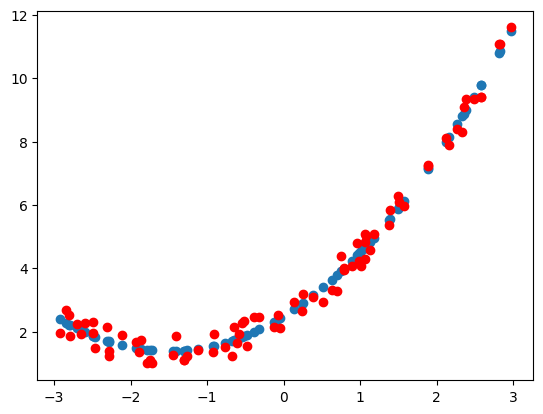

In [84]:
plt.scatter(X_train,regression.predict(X_train_poly))
plt.scatter(X_train,y_train,color="r")

In [85]:
poly=PolynomialFeatures(degree=3,include_bias=True)
X_train_poly=poly.fit_transform(X_train)
X_test_poly=poly.transform(X_test)

In [86]:
X_train_poly

array([[ 1.00000000e+00, -2.48954695e+00,  6.19784404e+00,
        -1.54298238e+01],
       [ 1.00000000e+00,  2.15868493e+00,  4.65992064e+00,
         1.00593005e+01],
       [ 1.00000000e+00, -1.89455769e+00,  3.58934883e+00,
        -6.80022841e+00],
       [ 1.00000000e+00,  2.12048439e+00,  4.49645406e+00,
         9.53466065e+00],
       [ 1.00000000e+00,  1.88815798e+00,  3.56514054e+00,
         6.73154854e+00],
       [ 1.00000000e+00,  1.05567481e+00,  1.11444930e+00,
         1.17649606e+00],
       [ 1.00000000e+00,  1.05531128e+00,  1.11368189e+00,
         1.17528106e+00],
       [ 1.00000000e+00, -3.88723480e-01,  1.51105944e-01,
        -5.87384283e-02],
       [ 1.00000000e+00, -2.11448562e+00,  4.47104942e+00,
        -9.45396968e+00],
       [ 1.00000000e+00, -3.18968483e-01,  1.01740893e-01,
        -3.24521382e-02],
       [ 1.00000000e+00,  1.49320867e+00,  2.22967214e+00,
         3.32936577e+00],
       [ 1.00000000e+00,  1.12194999e+00,  1.25877179e+00,
      

In [87]:
# Dont forget to include the bias parameter
from sklearn.metrics import r2_score
regression=LinearRegression()
regression.fit(X_train_poly,y_train)
y_pred=regression.predict(X_test_poly)
score=r2_score(y_test,y_pred)
print(score)

0.980793699726683


In [88]:
# Prediction of new dataset
X_new=np.linspace(-3,3,200).reshape(200,1)
X_new_poly=poly.transform(X_new)
X_new_poly

array([[ 1.00000000e+00, -3.00000000e+00,  9.00000000e+00,
        -2.70000000e+01],
       [ 1.00000000e+00, -2.96984925e+00,  8.82000455e+00,
        -2.61940839e+01],
       [ 1.00000000e+00, -2.93969849e+00,  8.64182723e+00,
        -2.54043665e+01],
       [ 1.00000000e+00, -2.90954774e+00,  8.46546804e+00,
        -2.46306834e+01],
       [ 1.00000000e+00, -2.87939698e+00,  8.29092700e+00,
        -2.38728702e+01],
       [ 1.00000000e+00, -2.84924623e+00,  8.11820409e+00,
        -2.31307624e+01],
       [ 1.00000000e+00, -2.81909548e+00,  7.94729931e+00,
        -2.24041955e+01],
       [ 1.00000000e+00, -2.78894472e+00,  7.77821267e+00,
        -2.16930052e+01],
       [ 1.00000000e+00, -2.75879397e+00,  7.61094417e+00,
        -2.09970269e+01],
       [ 1.00000000e+00, -2.72864322e+00,  7.44549380e+00,
        -2.03160961e+01],
       [ 1.00000000e+00, -2.69849246e+00,  7.28186157e+00,
        -1.96500486e+01],
       [ 1.00000000e+00, -2.66834171e+00,  7.12004747e+00,
      

In [89]:
y_new=regression.predict(X_new_poly)

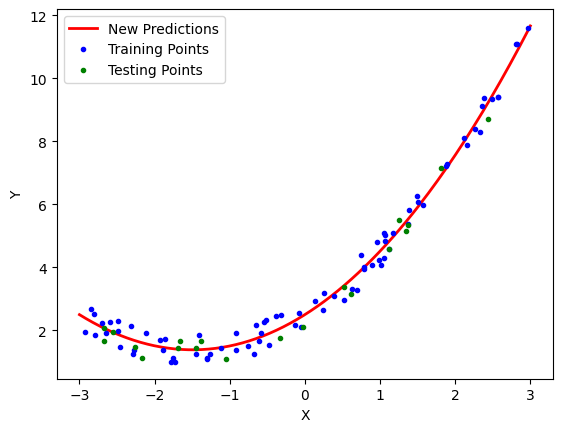

In [91]:
plt.plot(X_new,y_new,"r-",linewidth=2,label="New Predictions")
plt.plot(X_train,y_train,"b.",label="Training Points")
plt.plot(X_test,y_test,"g.",label="Testing Points")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.show()

In [94]:
# Few things
# when doing polynomial regression -> we transform the X_train to [1,X,X^2] using PolynomialFeatures(Here we give degree and fit_bias)
# Fit bias is not really reuqired in above because sklearn.linear regression includes the intercept 1 with the training data internally, 
# For the above practical we did fit bias =True and also applied linear regression on it, internally it would have created 2 constant values, which again was handled by sklearn to produce 1 constant intercept

In [ ]:
# Pipeline Concepts
from sklearn.pipeline import Pipeline

## Using pipeline concept I will create a generic function using which whatever degree I assign I will be able to see what type of curve it is fitting
def poly_regression(degree):
    X_new=np.linspace(-3,3,200).reshape(200,1)
    poly_features=PolynomialFeatures(degree=degree, include_bias=True)
    lin_reg=LinearRegression(fit_intercept=False) # Since we already included bias using poly_feaures (though it does not matter since it will get handled internally and the constants will get added)
    poly_regression=Pipeline([
        ("poly_features",poly_features),
        ("lin_reg",lin_reg)
    ])
    poly_regression.fit(X_train,y_train)
    y_pred_new=poly_regression.predict(X_new)
    # plotting prediction line
    plt.plot(X_new,y_pred_new,"r",label="Degree "+str(degree),linewidth=3)
    plt.plot(X_train,y_train,"b.",linewidth=3)
    plt.plot(X_test,y_test,"g.",linewidth=3)
    plt.legend(loc="upper left")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.show()

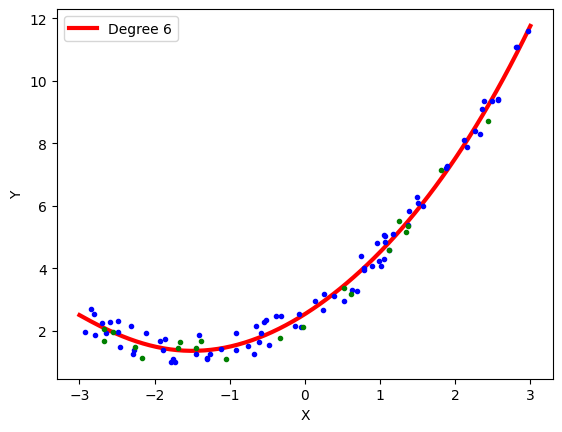

In [ ]:
poly_regression(6)
# Also one thing here the plot is x - X_train, y_train (these are not transformed values)
# No values in the plot is transformed one